**MLB Home Run Predictions Based On 2026 Batting Metrics**

**Overview:** This machine learning project uses data from the 2026 MLB season to predict home runs based on batting metrics. Workflow sections
include exploratory data analysis, visualization EDA, and machine learning. Ridge and Random Forest Regression models are evaluated with the final
model being selected based on cross validation performance. Regression metrics including R2 Score, MSE, and MAE are calculated to determine overall predictive performance. Feature evaluation is performed to determine which hitting metrics were most predictive of the home run continuous target variable. Finally, the model is tested on a sample player to predict their total home runs based on an input of batting metrics.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from pybaseball import batting_stats_bref, standings

In [2]:
print("Set Notebook & Plotting Options")
%matplotlib inline
plt.style.use('seaborn-v0_8')
output_divider = '=' * 130
fontweight='bold'
fontsize=12
pd.set_option('display.max_columns', None)
pd.options.display.float_format = '{:,.2f}'.format

Set Notebook & Plotting Options


**Section 1: Initial Exploratory Data Analysis**

In [3]:
df=batting_stats_bref(2026)
print("First Ten Rows Of Data:")
df.head(10)

First Ten Rows Of Data:


,Name,Age,#days,Lev,Tm,G,PA,AB,R,H,2B,3B,HR,RBI,BB,IBB,SO,HBP,SH,SF,GDP,SB,CS,BA,OBP,SLG,OPS,mlbID
1,CJ Abrams,25,13,Maj-NL,Washington,152,654,579,93,151,30,4,33,106,57,4,158,12,0,6,9,34,6,0.26,0.34,0.50,0.83,682928
2,Wilyer Abreu,27,10,Maj-AL,Boston,159,688,604,81,149,38,4,24,76,71,3,143,3,1,7,9,8,4,0.25,0.33,0.44,0.77,677800
3,Luisangel Acu\xc3\xb1a,24,10,Maj-AL,Chicago,104,225,211,24,48,4,0,2,13,9,0,44,1,2,2,5,20,6,0.23,0.26,0.28,0.54,682668
4,Ronald Acu\xc3\xb1a Jr.,28,3,Maj-NL,Atlanta,114,499,432,65,107,18,1,20,55,58,3,109,6,0,3,8,24,8,0.25,0.34,0.43,0.78,660670
5,Willy Adames,30,48,Maj-NL,San Francisco,121,505,465,62,107,25,1,21,51,37,0,139,2,0,1,3,5,2,0.23,0.29,0.42,0.71,642715
6,Jo Adell,27,0,Maj-AL,"Cleveland,Los Angeles",164,682,622,70,150,26,3,23,100,37,2,166,18,0,5,17,5,0,0.24,0.30,0.40,0.70,666176
7,Ozzie Albies,29,3,Maj-NL,Atlanta,169,713,639,89,152,29,2,24,78,51,2,109,9,0,14,8,4,4,0.24,0.30,0.40,0.70,645277
8,Kevin Alc\xc3\xa1ntara,23,48,Maj-NL,Chicago,24,28,25,6,6,0,0,1,6,2,0,11,0,0,1,1,0,1,0.24,0.29,0.36,0.65,682634
9,Blaze Alexander,27,32,Maj-AL,Baltimore,93,289,261,35,79,13,2,4,31,19,1,63,4,2,1,5,10,3,0.30,0.36,0.41,0.77,677942
10,Eliezer Alfonzo,26,31,Maj-NL,Los Angeles,13,28,28,3,5,2,0,0,4,0,0,3,0,0,0,0,0,0,0.18,0.18,0.25,0.43,672613


In [4]:
for cols in df.columns:
    print(cols)

Name
Age
#days
Lev
Tm
G
PA
AB
R
H
2B
3B
HR
RBI
BB
IBB
SO
HBP
SH
SF
GDP
SB
CS
BA
OBP
SLG
OPS
mlbID


In [5]:
print("Rename Features:")
print(output_divider)
df = df.rename(columns={
    'Name': 'Player_Name',
    'Age': 'Player_Age',
    'Lev': 'Level',
    'Tm': 'Team',
    'G': 'Games',
    'PA': 'Plate_Appearences',
    'R': 'Runs',
    'H': 'Hits',
    '2B': 'Doubles',
    '3B': 'Triples',
    'HR': 'Home_Runs',
    'BB': 'Walks',
    'HBP': 'Hit_By_Pitch',
    'SB': 'Stolen_Bases',
    'BA': 'Batting_Average'
})
for cols in df.columns:
    print(cols)

Rename Features:
Player_Name
Player_Age
#days
Level
Team
Games
Plate_Appearences
AB
Runs
Hits
Doubles
Triples
Home_Runs
RBI
Walks
IBB
SO
Hit_By_Pitch
SH
SF
GDP
Stolen_Bases
CS
Batting_Average
OBP
SLG
OPS
mlbID


In [6]:
print("Dataframe Shape:", df.shape, '|', 'Dataframe Size:', df.size)
print(output_divider)
print("Data Types & Initial Missing Data Inspection:")
df.info()

Dataframe Shape: (664, 28) | Dataframe Size: 18592
Data Types & Initial Missing Data Inspection:
<class 'pandas.core.frame.DataFrame'>
Index: 664 entries, 1 to 690
Data columns (total 28 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Player_Name        664 non-null    object 
 1   Player_Age         664 non-null    int64  
 2   #days              664 non-null    int64  
 3   Level              664 non-null    object 
 4   Team               664 non-null    object 
 5   Games              664 non-null    int64  
 6   Plate_Appearences  664 non-null    int64  
 7   AB                 664 non-null    int64  
 8   Runs               664 non-null    int64  
 9   Hits               664 non-null    int64  
 10  Doubles            664 non-null    int64  
 11  Triples            664 non-null    int64  
 12  Home_Runs          664 non-null    int64  
 13  RBI                664 non-null    int64  
 14  Walks              664 non-nul

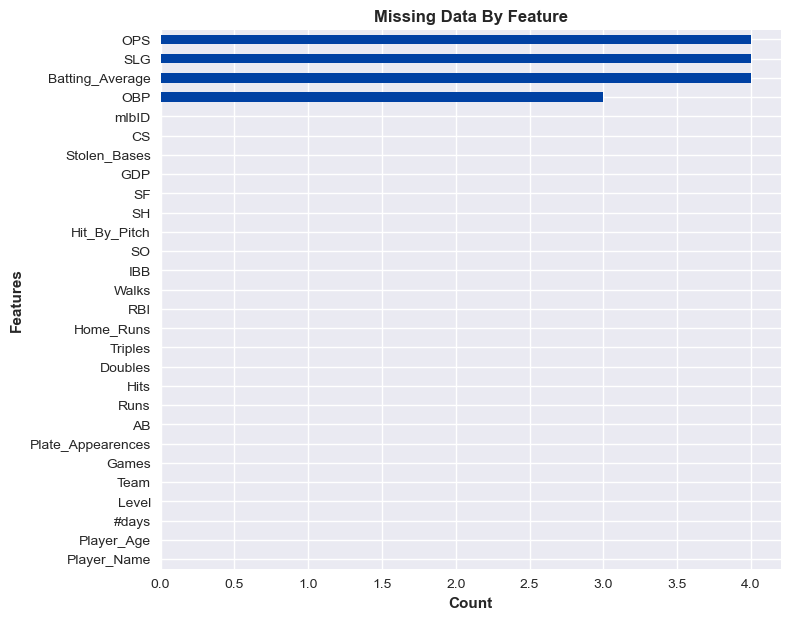

In [7]:
missing_data = df.isna().sum().sort_values(ascending=True)
plt.figure(figsize=(8,7))
missing_data.plot(kind='barh', color='#0041A3')
plt.title("Missing Data By Feature", fontweight=fontweight,
          fontsize=fontsize)
plt.xlabel("Count",
           fontweight=fontweight)
plt.ylabel("Features", fontweight=fontweight)
plt.show()

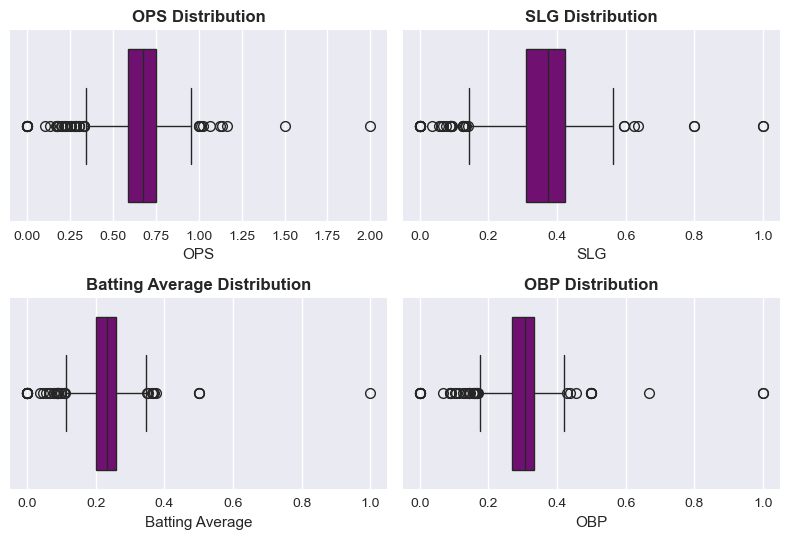

In [8]:
plt.subplot(2, 2, 1)
sns.boxplot(data=df, x='OPS', color='purple')
plt.title('OPS Distribution', fontweight=fontweight)
plt.title('OPS Distribution', 
         fontweight=fontweight)

plt.subplot(2, 2, 2)
sns.boxplot(data=df, x='SLG', color='purple')
plt.title('SLG Distribution',
         fontweight=fontweight)

plt.subplot(2, 2, 3)
sns.boxplot(data=df, x='Batting_Average', color='purple')
plt.title('Batting Average Distribution',
         fontweight=fontweight)
plt.xlabel("Batting Average")

plt.subplot(2, 2, 4)
sns.boxplot(data=df, x='OBP', color='purple')
plt.title('OBP Distribution', fontweight=fontweight)

plt.tight_layout()
plt.show()

In [9]:
print("Impute Missing Data With The Median:")
print(output_divider)
cols = ['OPS', 'SLG', 'Batting_Average', 'OBP']
df[cols] = df[cols].fillna(df[cols].median())
print("Confirm Missing Data Is Imputed:")
missing_data = df.isna().sum()
print(output_divider)
print(missing_data)

Impute Missing Data With The Median:
Confirm Missing Data Is Imputed:
Player_Name          0
Player_Age           0
#days                0
Level                0
Team                 0
Games                0
Plate_Appearences    0
AB                   0
Runs                 0
Hits                 0
Doubles              0
Triples              0
Home_Runs            0
RBI                  0
Walks                0
IBB                  0
SO                   0
Hit_By_Pitch         0
SH                   0
SF                   0
GDP                  0
Stolen_Bases         0
CS                   0
Batting_Average      0
OBP                  0
SLG                  0
OPS                  0
mlbID                0
dtype: int64


In [10]:
print("Summary Statistics On Numeric Features:")
df.describe()

Summary Statistics On Numeric Features:


,Player_Age,#days,Games,Plate_Appearences,AB,Runs,Hits,Doubles,Triples,Home_Runs,RBI,Walks,IBB,SO,Hit_By_Pitch,SH,SF,GDP,Stolen_Bases,CS,Batting_Average,OBP,SLG,OPS,mlbID
count,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00
mean,27.68,35.18,78.45,279.63,248.40,33.05,60.52,11.35,1.02,8.47,31.57,24.86,0.83,61.97,3.23,1.04,1.97,4.78,5.00,1.48,0.22,0.30,0.36,0.65,"672,543.51"
std,3.67,43.84,52.51,222.62,196.63,29.19,51.92,10.22,1.67,9.27,28.60,24.09,2.21,49.76,4.15,1.93,2.26,4.75,7.78,2.26,0.07,0.08,0.12,0.18,"52,598.60"
min,20.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"457,705.00"
25%,25.00,13.00,29.00,76.75,69.00,7.00,13.00,3.00,0.00,1.00,7.00,5.00,0.00,20.75,0.00,0.00,0.00,1.00,0.00,0.00,0.20,0.27,0.31,0.59,"663,572.50"
50%,27.00,13.00,80.00,236.00,213.50,25.00,48.00,8.00,0.00,5.00,23.00,18.00,0.00,51.00,2.00,0.00,1.00,4.00,2.00,1.00,0.23,0.31,0.37,0.68,"672,742.50"
75%,30.00,45.25,126.25,468.25,412.00,54.00,99.00,19.00,1.00,13.00,51.00,39.00,1.00,95.00,5.00,1.00,3.00,8.00,6.00,2.00,0.26,0.33,0.42,0.75,"688,625.75"
max,40.00,195.00,169.00,736.00,656.00,119.00,191.00,40.00,17.00,46.00,116.00,111.00,33.00,238.00,33.00,13.00,14.00,26.00,49.00,14.00,1.00,1.00,1.00,2.00,"828,599.00"


In [11]:
print("Summary Level Statistics On Categorical Features:")
df.describe(include='object')

Summary Level Statistics On Categorical Features:


,Player_Name,Level,Team
count,664,664,664
unique,663,3,90
top,Max Muncy,Maj-AL,Los Angeles
freq,2,311,42


In [12]:
team_inspection = df['Team'].unique()
print(team_inspection)
print(output_divider)
print("Team Feature Includes In-Season Trades.")

['Washington' 'Boston' 'Chicago' 'Atlanta' 'San Francisco'
 'Cleveland,Los Angeles' 'Baltimore' 'Los Angeles' 'Houston' 'New York'
 'Colorado' 'San Diego' 'Tampa Bay' 'Minnesota' 'Arizona'
 'Chicago,Cleveland,New York' 'Seattle' 'Philadelphia,San Francisco'
 'Cincinnati' 'Milwaukee' 'Detroit' 'St. Louis' 'Cleveland,San Francisco'
 'Chicago,Los Angeles' 'Toronto' 'Arizona,Houston'
 'Atlanta,Chicago,Pittsburgh' 'Cleveland' 'Philadelphia' 'Athletics'
 'Pittsburgh' 'Texas' 'Cincinnati,Cleveland' 'Cincinnati,New York'
 'Kansas City' 'Miami' 'Kansas City,Texas' 'Chicago,Colorado'
 'Cleveland,Seattle' 'Los Angeles,Tampa Bay' 'New York,Washington'
 'Chicago,Pittsburgh' 'Chicago,New York' 'Athletics,Boston,San Francisco'
 'Chicago,Houston,San Diego' 'Chicago,San Diego' 'Athletics,Atlanta'
 'Los Angeles,Toronto' 'Miami,Tampa Bay' 'Chicago,Philadelphia'
 'Baltimore,Cincinnati,Miami' 'Athletics,New York' 'Boston,Detroit'
 'Chicago,Texas' 'San Francisco,Seattle' 'Atlanta,Tampa Bay'
 'Boston,San Fra

**Section 2: Visualization EDA**

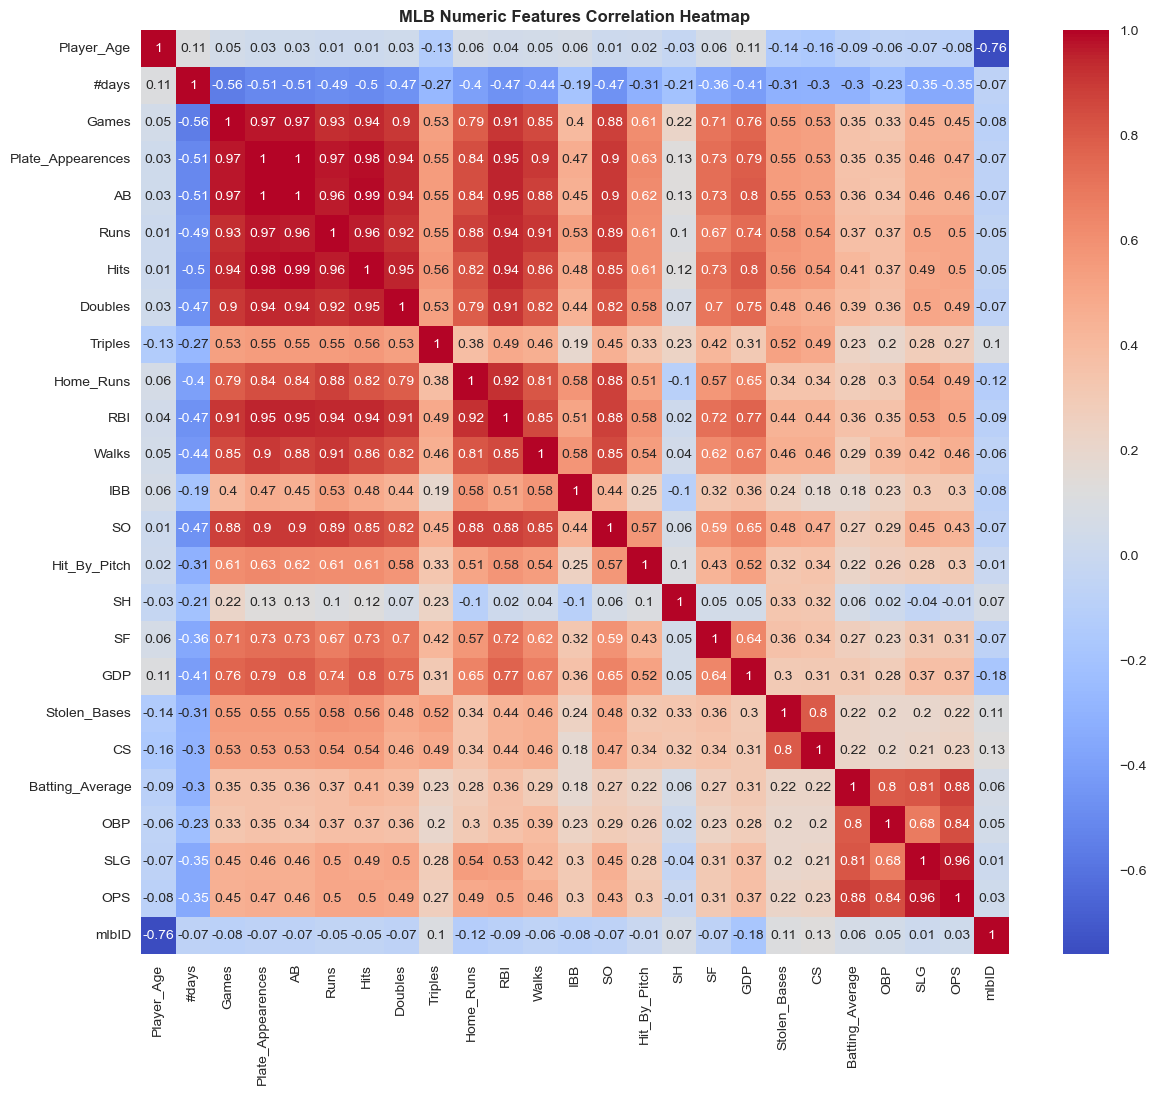

In [13]:
corr = df.select_dtypes(include=['int64', 'float64']).corr().round(2)
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', annot=True)
plt.title("MLB Numeric Features Correlation Heatmap",
          fontweight=fontweight, fontsize=fontsize)
plt.show()

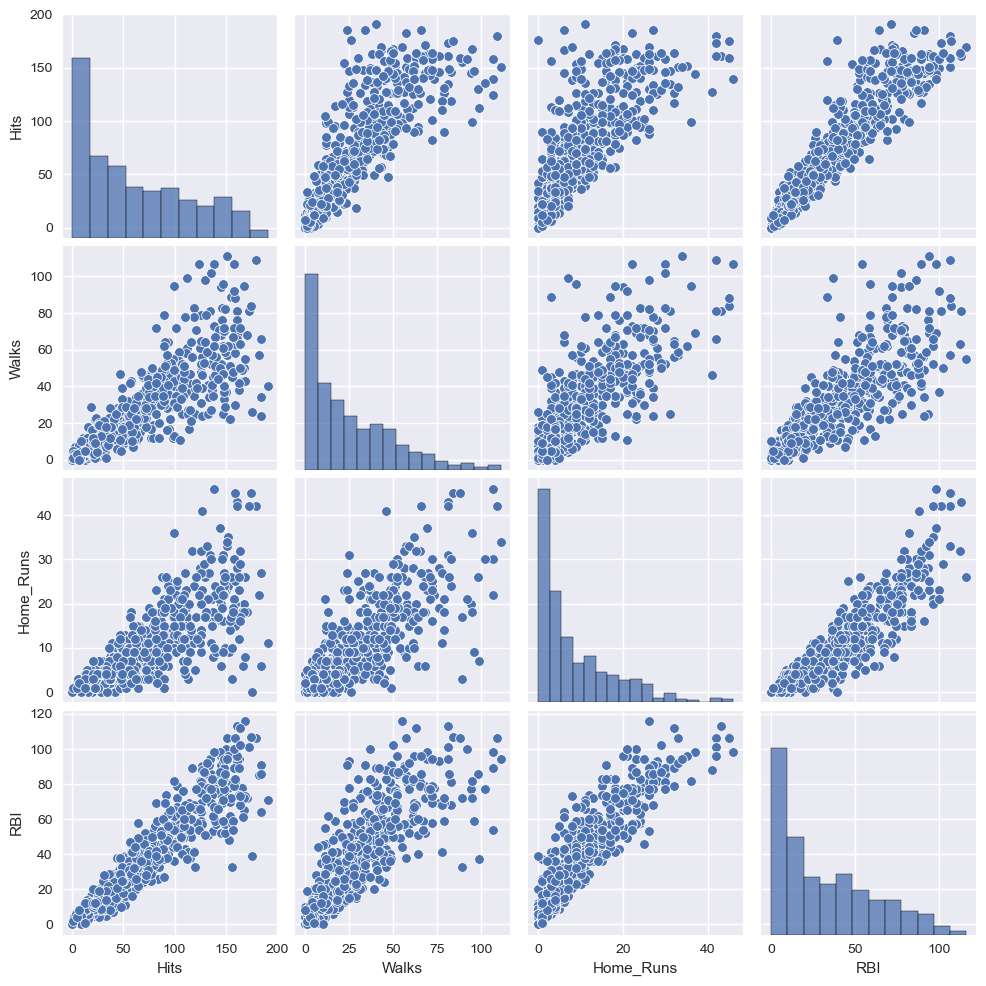

In [14]:
sns.pairplot(data=df, vars=[
    'Hits',  'Walks', 'Home_Runs', 'RBI'])
plt.show()

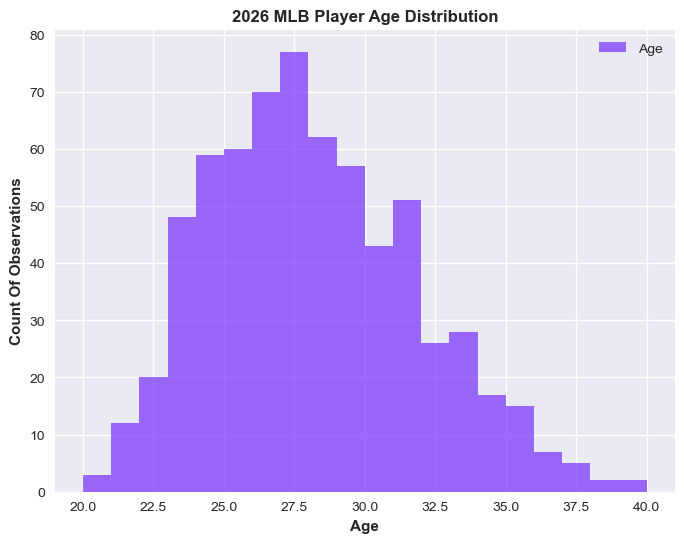

In [15]:
plt.figure(figsize=(8,6))
plt.hist(x=df['Player_Age'], color='#772EFF',
        bins=20, alpha=0.7, label='Age')
plt.title("2026 MLB Player Age Distribution",
          fontweight= fontweight, fontsize=fontsize)
plt.xlabel('Age',
           fontweight=fontweight)
plt.ylabel("Count Of Observations",
           fontweight=fontweight)
plt.legend(loc='upper right')
plt.show()

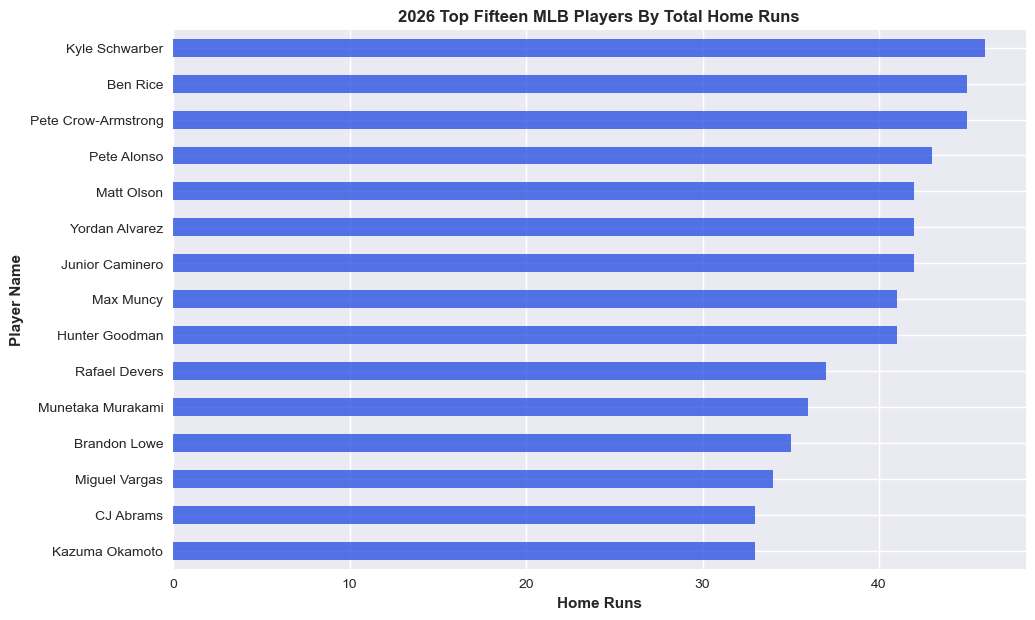

In [16]:
home_runs = df.groupby('Player_Name')['Home_Runs'].sum().sort_values(ascending=True).tail(15)
plt.figure(figsize=(11,7))
home_runs.plot(kind='barh', color='#1F49E0', alpha=0.75)
plt.title("2026 Top Fifteen MLB Players By Total Home Runs",
          fontweight=fontweight, fontsize=fontsize)
plt.xlabel('Home Runs',
            fontweight=fontweight)
plt.ylabel("Player Name",
           fontweight=fontweight)
plt.show()

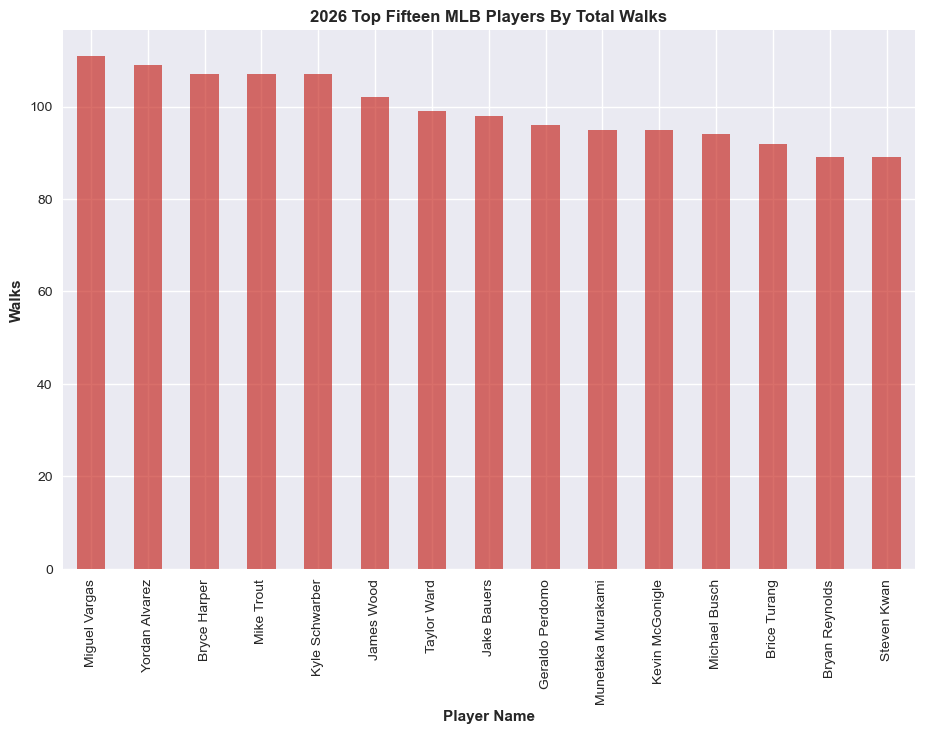

In [17]:
walks = df.groupby('Player_Name')['Walks'].sum().sort_values(ascending=False).head(15)
plt.figure(figsize=(11,7))
walks.plot(kind='bar', color='#C11007', alpha=0.6)
plt.title("2026 Top Fifteen MLB Players By Total Walks",
          fontweight=fontweight, fontsize=fontsize)
plt.xlabel('Player Name',
            fontweight=fontweight)
plt.ylabel("Walks",
           fontweight=fontweight)
plt.show()

**Section 3: Machine Learning**

**3A: Data Preprocessing**

In [18]:
print("Data Types:")
print(df.dtypes)
print(output_divider)
df.head()

Data Types:
Player_Name           object
Player_Age             int64
#days                  int64
Level                 object
Team                  object
Games                  int64
Plate_Appearences      int64
AB                     int64
Runs                   int64
Hits                   int64
Doubles                int64
Triples                int64
Home_Runs              int64
RBI                    int64
Walks                  int64
IBB                    int64
SO                     int64
Hit_By_Pitch           int64
SH                     int64
SF                     int64
GDP                    int64
Stolen_Bases           int64
CS                     int64
Batting_Average      float64
OBP                  float64
SLG                  float64
OPS                  float64
mlbID                  int64
dtype: object


,Player_Name,Player_Age,#days,Level,Team,Games,Plate_Appearences,AB,Runs,Hits,Doubles,Triples,Home_Runs,RBI,Walks,IBB,SO,Hit_By_Pitch,SH,SF,GDP,Stolen_Bases,CS,Batting_Average,OBP,SLG,OPS,mlbID
1,CJ Abrams,25,13,Maj-NL,Washington,152,654,579,93,151,30,4,33,106,57,4,158,12,0,6,9,34,6,0.26,0.34,0.50,0.83,682928
2,Wilyer Abreu,27,10,Maj-AL,Boston,159,688,604,81,149,38,4,24,76,71,3,143,3,1,7,9,8,4,0.25,0.33,0.44,0.77,677800
3,Luisangel Acu\xc3\xb1a,24,10,Maj-AL,Chicago,104,225,211,24,48,4,0,2,13,9,0,44,1,2,2,5,20,6,0.23,0.26,0.28,0.54,682668
4,Ronald Acu\xc3\xb1a Jr.,28,3,Maj-NL,Atlanta,114,499,432,65,107,18,1,20,55,58,3,109,6,0,3,8,24,8,0.25,0.34,0.43,0.78,660670
5,Willy Adames,30,48,Maj-NL,San Francisco,121,505,465,62,107,25,1,21,51,37,0,139,2,0,1,3,5,2,0.23,0.29,0.42,0.71,642715


In [19]:
X = df.drop(columns=['Team', 'Level', 'mlbID', 'Player_Name','Home_Runs'], axis=1)
y = df['Home_Runs']
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
print("Numeric Features:", numeric_features)
print(output_divider)
print("Target Variable:", y.name)

Numeric Features: ['Player_Age', '#days', 'Games', 'Plate_Appearences', 'AB', 'Runs', 'Hits', 'Doubles', 'Triples', 'RBI', 'Walks', 'IBB', 'SO', 'Hit_By_Pitch', 'SH', 'SF', 'GDP', 'Stolen_Bases', 'CS', 'Batting_Average', 'OBP', 'SLG', 'OPS']
Target Variable: Home_Runs


In [20]:
print("Split training/testing data, set cross validatons and random_state.")
random_state = 42
cv = KFold(n_splits=5, shuffle=True, random_state=random_state)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=random_state, test_size=0.20)

Split training/testing data, set cross validatons and random_state.


In [21]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())])

data_preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_transformer, numeric_features)])

**3B: Ridge Regression**

In [22]:
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', data_preprocessor),
    ('Ridge', Ridge(random_state=random_state, alpha=1.0))])

In [23]:
Ridge_Untuned_Crossval_Scores = cross_val_score(ridge_pipeline, X_train, y_train, scoring ='r2', cv=cv)
Ridge_Untuned_Crossval_Mean = Ridge_Untuned_Crossval_Scores.mean()
print("Untuned Ridge Cross Validation R2 Scores:", Ridge_Untuned_Crossval_Scores)
print(output_divider)
print("Untuned Ridge Mean Cross Validation R2 Score:", Ridge_Untuned_Crossval_Mean)

Untuned Ridge Cross Validation R2 Scores: [0.93454677 0.93765964 0.93856402 0.92214351 0.91843494]
Untuned Ridge Mean Cross Validation R2 Score: 0.9302697768524564


**3C: Ridge Regression Hyperparameter Tuning**

In [24]:
alpha_grid = {'Ridge__alpha': np.logspace(-1,1,10)}
alpha_search = GridSearchCV(ridge_pipeline, param_grid=alpha_grid, cv=cv, scoring='r2')
alpha_search.fit(X_train, y_train)
optimal_alpha = (alpha_search.best_params_)
print("Optimal Alpha Value:", optimal_alpha)

Optimal Alpha Value: {'Ridge__alpha': np.float64(1.291549665014884)}


In [25]:
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', data_preprocessor),
    ('Ridge', Ridge(random_state=random_state, alpha=1.29))])

In [26]:
Ridge_Tuned_Crossval_Scores = cross_val_score(ridge_pipeline, X_train, y_train, scoring ='r2', cv=cv)
Ridge_Tuned_Crossval_Mean = Ridge_Tuned_Crossval_Scores.mean()
print("Tuned Ridge Cross Validation R2 Scores:", Ridge_Tuned_Crossval_Scores)
print(output_divider)
print("Tuned Ridge Mean Cross Validation R2 Score:", Ridge_Tuned_Crossval_Mean)

Tuned Ridge Cross Validation R2 Scores: [0.93426138 0.93766605 0.93836792 0.92222251 0.91887076]
Tuned Ridge Mean Cross Validation R2 Score: 0.9302777254559411


In [27]:
comments = """Ridge regression hyperparameter tuning had negligible impact on model performance. """
print(comments)

Ridge regression hyperparameter tuning had negligible impact on model performance. 


**3D: Random Forest Regressor**

In [28]:
RF_pipeline = Pipeline(steps=[
    ('preprocessor', data_preprocessor),
    ('Random_Forest', RandomForestRegressor(random_state=random_state,
                                            max_depth=5, n_estimators = 50))])

In [29]:
RF_Untuned_Crossval_Scores = cross_val_score(RF_pipeline, X_train, y_train, scoring='r2', cv=cv)
RF_Untuned_Crossval_Mean = RF_Untuned_Crossval_Scores.mean()
print("Untuned Random Forest Cross Validation R2 Scores:", RF_Untuned_Crossval_Scores)
print(output_divider)
print("Untuned Random Forest Mean Cross Validation R2 Score:", RF_Untuned_Crossval_Mean)

Untuned Random Forest Cross Validation R2 Scores: [0.91719839 0.90645821 0.91162218 0.92813675 0.93000636]
Untuned Random Forest Mean Cross Validation R2 Score: 0.9186843788785758


**3E: Random Forest Regressor Hyperparameter Tuning**

In [30]:
rf_grid = {'Random_Forest__max_depth': [None, 4, 8],
             'Random_Forest__n_estimators': [50, 100, 150],
           'Random_Forest__max_features': [.5 ,1, 'sqrt']
            }
rf_search = GridSearchCV(RF_pipeline, param_grid=rf_grid, cv=cv, scoring='r2', verbose=1)
rf_search.fit(X_train, y_train)
print(output_divider)
print("Optimal Random Forest Parameters:", rf_search.best_params_)

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Optimal Random Forest Parameters: {'Random_Forest__max_depth': None, 'Random_Forest__max_features': 0.5, 'Random_Forest__n_estimators': 150}


In [31]:
RF_pipeline = Pipeline(steps=[
    ('preprocessor', data_preprocessor),
    ('Random_Forest', RandomForestRegressor(random_state=random_state,
                                            max_depth=None, n_estimators = 150, max_features=0.5))])

In [32]:
RF_Tuned_Crossval_Scores = cross_val_score(RF_pipeline, X_train, y_train, scoring='r2', cv=cv)
RF_Tuned_Crossval_Mean = RF_Tuned_Crossval_Scores.mean()
print("Tuned Random Forest Cross Validation R2 Scores:", RF_Tuned_Crossval_Scores)
print(output_divider)
print("Tuned Random Forest Mean Cross Validation R2 Score:", RF_Tuned_Crossval_Mean)

Tuned Random Forest Cross Validation R2 Scores: [0.93677163 0.923115   0.92496548 0.93509242 0.93806578]
Tuned Random Forest Mean Cross Validation R2 Score: 0.9316020623505871


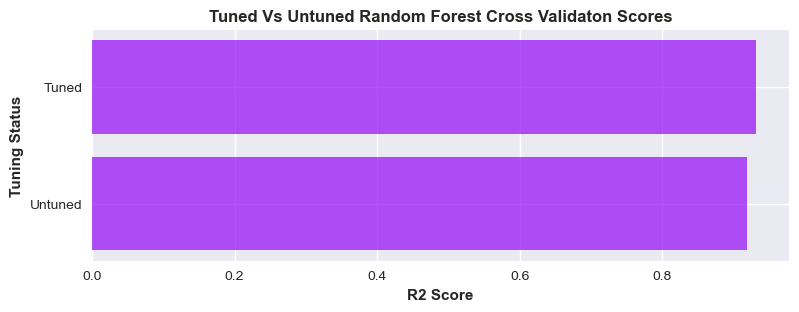

In [33]:
tuning_status = ["Untuned", "Tuned"]
rf_scores = [RF_Untuned_Crossval_Mean, RF_Tuned_Crossval_Mean]
plt.figure(figsize=(9,3))
plt.barh(tuning_status, rf_scores, color='#9308F7',
         alpha=0.7)
plt.title("Tuned Vs Untuned Random Forest Cross Validaton Scores",
          fontweight=fontweight, fontsize=fontsize)
plt.xlabel("R2 Score",
           fontweight=fontweight)
plt.ylabel("Tuning Status", fontweight=fontweight)
plt.show()

In [34]:
comments = '''Random Forest hyperparameter tuning marginally improved R2 cross validation scoring.'''
print(comments)

Random Forest hyperparameter tuning marginally improved R2 cross validation scoring.


**3F: Model Selection**

In [35]:
print("Tuned Ridge Regression Mean Cross Validation Score:", Ridge_Tuned_Crossval_Mean)
print(output_divider)
print("Tuned Random Forest Regression Mean Cross Validation Score:", RF_Tuned_Crossval_Mean)

Tuned Ridge Regression Mean Cross Validation Score: 0.9302777254559411
Tuned Random Forest Regression Mean Cross Validation Score: 0.9316020623505871


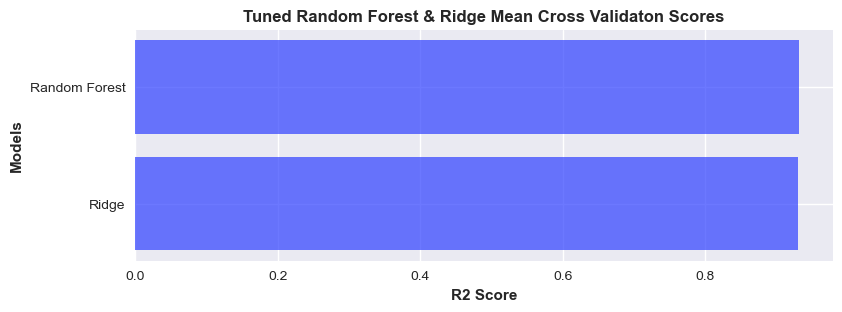

In [36]:
models = ["Ridge", "Random Forest"]
scores = [Ridge_Tuned_Crossval_Mean, RF_Tuned_Crossval_Mean]
plt.figure(figsize=(9,3))
plt.barh(models, scores, color='#2E3FFF',
         alpha=0.7)
plt.title("Tuned Random Forest & Ridge Mean Cross Validaton Scores",
          fontweight=fontweight, fontsize=fontsize)
plt.xlabel("R2 Score",
           fontweight=fontweight)
plt.ylabel("Models", fontweight=fontweight)
plt.show()

In [37]:
comments = "The Random Forest Regressor marginally outperformed Ridge Regression and will be selected as the final model."
print(comments)

The Random Forest Regressor marginally outperformed Ridge Regression and will be selected as the final model.


**3G: Model Fitting & Evaluation**

In [38]:
print("Fit Training Data To Random Forest Pipeline:")
print(output_divider)
RF_pipeline.fit(X_train, y_train)

Fit Training Data To Random Forest Pipeline:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('Random_Forest', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers cont

In [39]:
y_pred = RF_pipeline.predict(X_test)
RF_Test_Score = np.round(RF_pipeline.score(X_test, y_test),2)
RF_Training_Score = np.round(RF_pipeline.score(X_train, y_train),2)
MAE = mean_absolute_error(y_test, y_pred)
MSE = mean_squared_error (y_test, y_pred)
print("Random Forest Testing Data Score:", RF_Test_Score)
print(output_divider)
print("Random Forest Training Data Score:", RF_Training_Score)
print(output_divider)
print("Mean Absolute Error:", MAE)
print(output_divider)
print("Mean Squared Error:", MSE)

Random Forest Testing Data Score: 0.93
Random Forest Training Data Score: 0.99
Mean Absolute Error: 1.537593984962406
Mean Squared Error: 5.679853968253969


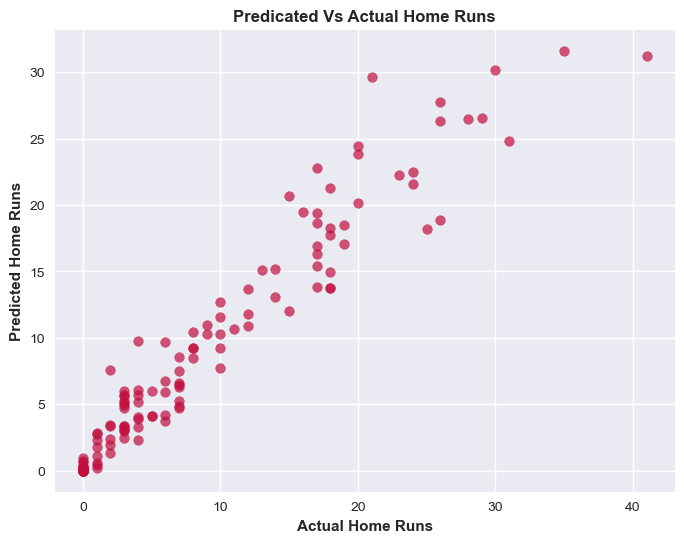

In [40]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, color='#C20F3F', alpha=0.7, marker='o')
plt.title("Predicated Vs Actual Home Runs",
          fontweight=fontweight, fontsize=fontsize)
plt.xlabel("Actual Home Runs",
           fontweight=fontweight)
plt.ylabel("Predicted Home Runs",
           fontweight=fontweight)
plt.show()

**3H: Feature Evaluation**

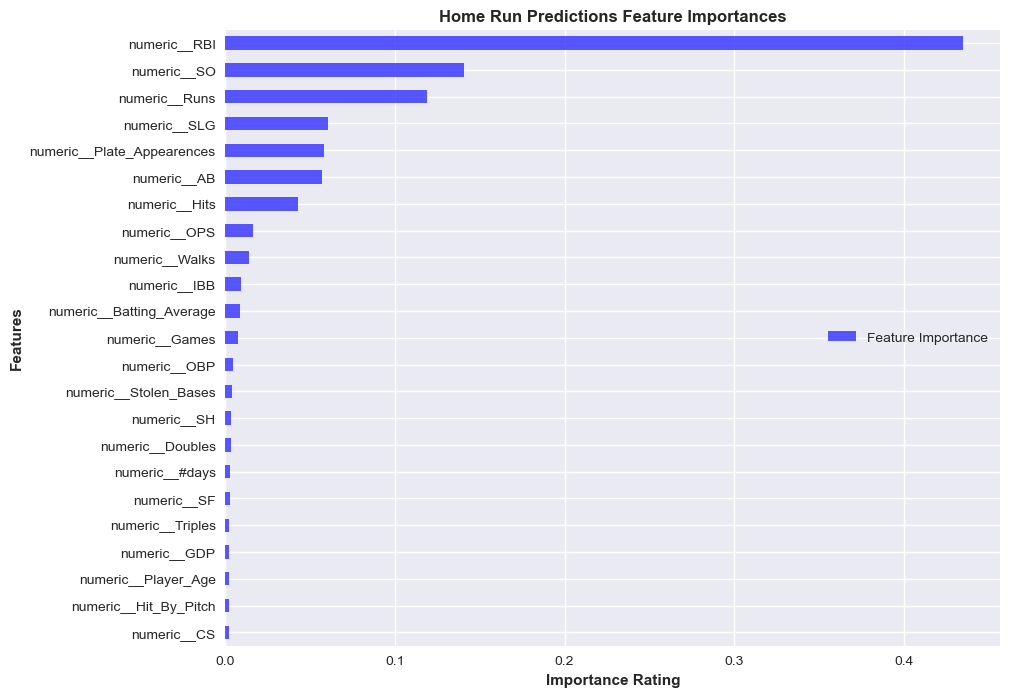

In [41]:
rf_features = RF_pipeline.named_steps['preprocessor'].get_feature_names_out()
rf_values = RF_pipeline.named_steps['Random_Forest'].feature_importances_
feature_values = pd.Series(rf_values, index=rf_features).sort_values()
plt.figure(figsize=(10,8))
feature_values.plot(kind='barh', color='#312EFF',
                    alpha=0.8, label='Feature Importance')
plt.title("Home Run Predictions Feature Importances",
          fontweight=fontweight, fontsize=fontsize)
plt.xlabel("Importance Rating",
           fontweight=fontweight)
plt.ylabel("Features",
           fontweight=fontweight)
plt.legend(loc='center right')
plt.show()

**3I: Model Testing With Sample Player**

In [42]:
print("Features:", X.columns.tolist())
print(output_divider)
print("Feature Summary Statistics:")
X.describe()

Features: ['Player_Age', '#days', 'Games', 'Plate_Appearences', 'AB', 'Runs', 'Hits', 'Doubles', 'Triples', 'RBI', 'Walks', 'IBB', 'SO', 'Hit_By_Pitch', 'SH', 'SF', 'GDP', 'Stolen_Bases', 'CS', 'Batting_Average', 'OBP', 'SLG', 'OPS']
Feature Summary Statistics:


,Player_Age,#days,Games,Plate_Appearences,AB,Runs,Hits,Doubles,Triples,RBI,Walks,IBB,SO,Hit_By_Pitch,SH,SF,GDP,Stolen_Bases,CS,Batting_Average,OBP,SLG,OPS
count,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00,664.00
mean,27.68,35.18,78.45,279.63,248.40,33.05,60.52,11.35,1.02,31.57,24.86,0.83,61.97,3.23,1.04,1.97,4.78,5.00,1.48,0.22,0.30,0.36,0.65
std,3.67,43.84,52.51,222.62,196.63,29.19,51.92,10.22,1.67,28.60,24.09,2.21,49.76,4.15,1.93,2.26,4.75,7.78,2.26,0.07,0.08,0.12,0.18
min,20.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,25.00,13.00,29.00,76.75,69.00,7.00,13.00,3.00,0.00,7.00,5.00,0.00,20.75,0.00,0.00,0.00,1.00,0.00,0.00,0.20,0.27,0.31,0.59
50%,27.00,13.00,80.00,236.00,213.50,25.00,48.00,8.00,0.00,23.00,18.00,0.00,51.00,2.00,0.00,1.00,4.00,2.00,1.00,0.23,0.31,0.37,0.68
75%,30.00,45.25,126.25,468.25,412.00,54.00,99.00,19.00,1.00,51.00,39.00,1.00,95.00,5.00,1.00,3.00,8.00,6.00,2.00,0.26,0.33,0.42,0.75
max,40.00,195.00,169.00,736.00,656.00,119.00,191.00,40.00,17.00,116.00,111.00,33.00,238.00,33.00,13.00,14.00,26.00,49.00,14.00,1.00,1.00,1.00,2.00


In [43]:
sample_player = {
'Player_Age': 29,
 '#days' : 50,
 'Games': 120,
 'Plate_Appearences': 360,
 'AB': 270,
 'Runs': 70,
 'Hits': 80,
 'Doubles': 13,
 'Triples': 2,
 'RBI': 42,
 'Walks': 15,
 'IBB': 1.2,
 'SO': 53,
 'Hit_By_Pitch': 2,
 'SH':1,
 'SF': 2,
 'GDP': 3,
 'Stolen_Bases': 12,
 'CS': 1,
 'Batting_Average': 0.24,
 'OBP': 0.28,
 'SLG': 0.45,
 'OPS': 0.65}

sample_player_df = pd.DataFrame([sample_player])

sample_player_df = sample_player_df[X_train.columns]

home_run_prediction = RF_pipeline.predict(sample_player_df)

print("Predicted Home Runs For Sample Player:", home_run_prediction)

Predicted Home Runs For Sample Player: [11.6]


**Project Findings:** The Random Forest Regression model achieved an R2 score of 0.99 on training data and 0.93 on testing data. The difference between these scores indicates some overfitting, although the model maintained strong performance on unseen data. The MAE score of 1.53 indicates home run predictions differed by 1.53 home runs on average. Overall, these results demonstrate strong performance in estimating home run production from same-season batting metrics. This model can serve as a reference point for estimating home run production under comparable playing conditions. However, this model does not account for injuries, age-related performance fluctuations, and year-to-year alotted playing time. 

The Ridge and Random Forest Regression models achieved nearly identical training scores indicating both models were capable of capturing the variance in the data. RBI's, strikeouts, runs scored, slugging percentage, plate appearences, and hits were the most predictive features on the home run continous target variable.